Deliverable 1

Ida Sofie Ramsli & Emilie Marthinsen Kålås




------------------------------------------------------
------------------------Task 1------------------------

Data retrieved from frost.met.no!


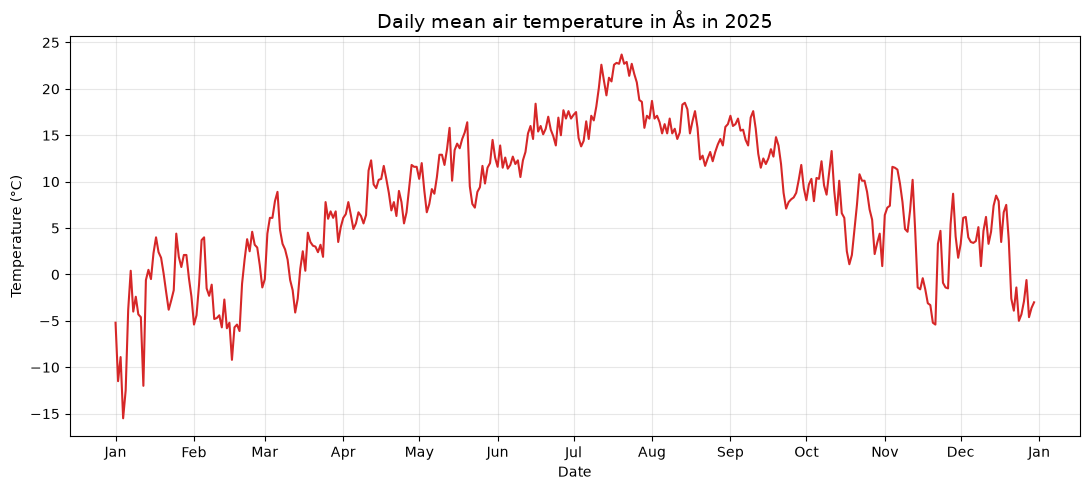


Summary of daily mean air temperature, 2025
------------------------------------------
Statistic  Temperature (°C)
     Mean               7.9
   Median               8.4
      Min             -15.5
      Max              23.7


In [ ]:
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates



client_id_file = Path.home() / "frost_client_id.txt"       # reads the client ID from a file in the home directory
client_id = client_id_file.read_text().strip()             # removes any spaces from the client ID string

endpoint = "https://frost.met.no/observations/v0.jsonld"    # Frost API endpoint for observations
parameters = {                                              # parameters for the API request
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r = requests.get(endpoint, parameters, auth=(client_id, ""))    # make the GET request to the Frost API with the specified parameters and authentication
json_data = r.json()                                            # extract the data from the response



if r.status_code == 200:                                  # check if the request was successful (status code 200 indicates success)
    print('Data retrieved from frost.met.no!')
else:
    print(f"Error: {r.status_code} - {json_data['error']['message']}")   # print an error message if the request was not successful
    raise SystemExit                                                      # exit the program if there was an error with the request



#---------------------------------------------------------------------------------------------------------------------


rows = []                                   # create an empty list to store the data rows for the DataFrame
for item in json_data["data"]:              # iterate through each item in the "data" field
    observation = item["observations"][0]   # one daily mean per reference time
    rows.append(                            # adds the data for each observation to the rows list as a dictionary with keys "time" and "temperature"
        {
            "time": pd.to_datetime(item["referenceTime"]),
            "temperature": observation["value"],
        }
    )

df = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)      # creates a dataframe from the rows list, sorts it by time, and resets the index



fig, ax = plt.subplots(figsize=(11, 5))         # creates a figure and axes for the plot with a specified size
ax.plot(df["time"], df["temperature"], color="tab:red")      # plots the date on the x-axis and daily mean air temperature data on the y-axis
ax.set_title("Daily mean air temperature in Ås in 2025", fontsize=14)
ax.set_xlabel("Date")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylabel("Temperature (°C)")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


temp = df["temperature"]
summary = pd.DataFrame(                         # creates a summary of statistics for the daily mean air temperature
    {
        "Statistic": ["Mean", "Median", "Min", "Max"],
        "Temperature (°C)": [temp.mean(), temp.median(), temp.min(), temp.max()],
    }
)

print("\nSummary of daily mean air temperature, 2025")
print("------------------------------------------")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.1f}"))

Discussion of results - Task 1:
    
    We found that the daily mean temperature during 2025 varied a lot during this year, whereas the minimum was -15.5 degrees celcius and the maximum was 23.7 degrees celcius, which is a 39.2 degree difference. There was an updards curve towards a peak in July (which is excepted since the temperatures generally are higher during the summer), and subsequently a decrease in the temperature in the following months. An interesting thing we found, is that the temperature varied a lot during some months, especially during January where the temperature had a 15 degree increase during the span of a few days.


------------------------------------------------------
------------------------Task 2------------------------

Precipitation data retrieved from frost.met.no!


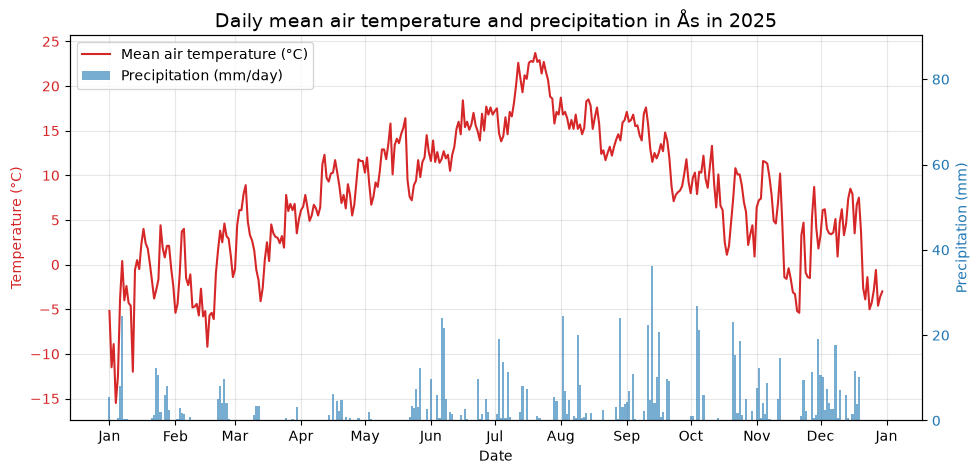

In [6]:
parameters_precipitation = {                                # parameters for the API request (precipitation over 24 hours)
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r_precipitation = requests.get(endpoint, parameters_precipitation, auth=(client_id, ""))    # make the GET request to the Frost API with the precipitation parameters
json_precipitation = r_precipitation.json()                                                 # extract the data from the response



if r_precipitation.status_code == 200:                           # check if the request was successful (status code 200 indicates success)
    print('Precipitation data retrieved from frost.met.no!')
else:
    print(f"Error: {r_precipitation.status_code} - {json_precipitation['error']['message']}")   # print an error message if the request was not successful
    raise SystemExit                                                                            # stop the script here

rows_precipitation = []                                # create an empty list to store the data rows for the DataFrame
for item in json_precipitation["data"]:                # iterate through each item in the "data" field
    observation = item["observations"][0]              # one daily sum per reference time
    rows_precipitation.append(                         # adds the data for each observation to the list as a dictionary with keys "time" and "precipitation"
        {
            "time": pd.to_datetime(item["referenceTime"]),
            "precipitation": observation["value"],
        }
    )



df_precipitation = pd.DataFrame(rows_precipitation).sort_values("time").reset_index(drop=True)   # creates a dataframe from the rows list, sorts it by time, and resets the index

df_both = pd.merge(df, df_precipitation, on="time", how="outer").sort_values("time")      # combines temperature and precipitation by date




fig, ax = plt.subplots(figsize=(11, 5))         # creates a figure and axes for the plot with a specified size
ax2 = ax.twinx()                                # creates a second y-axis on the right side that shares the same x-axis

bars = ax2.bar(df_both["time"], df_both["precipitation"], width=1.0, color="tab:blue", alpha=0.6, label="Precipitation (mm/day)")   # precipitation as bars (a total for each day)
ax2.set_ylabel("Precipitation (mm)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")
ax2.set_ylim(0, df_both["precipitation"].max() * 2.5)       # extra headroom so the bars stay in the lower part and do not hide the line

(line,) = ax.plot(df_both["time"], df_both["temperature"], color="tab:red", label="Mean air temperature (°C)")   # temperature as a line (changes continuously)
ax.set_ylabel("Temperature (°C)", color="tab:red")
ax.tick_params(axis="y", labelcolor="tab:red")

ax.set_title("Daily mean air temperature and precipitation in Ås in 2025", fontsize=14)
ax.set_xlabel("Date")

ax.xaxis.set_major_locator(mdates.MonthLocator())           # one tick per month
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.3)
ax.legend(handles=[line, bars], loc="upper left")      
plt.show()

Discussion of results - task 2:

    We can't see any clear correlation between the temperature and percipitation. The heaviest day was in September when the temperature was approximately 12 degrees celcius, but there was also a lot of days with percipitation during the winter when the temperatures were lower. There are days with a lot a percipitation during all of the seasons except for spring, which might indicate that the rising temperature might have an impact on the amount of percipitation, but we can't know this for certain by looking at this data.

------------------------------------------------------
------------------------Task 3------------------------

Temperature data from 2025 has been fetched
Historical temperature data from 1925 has been fetched
365 365


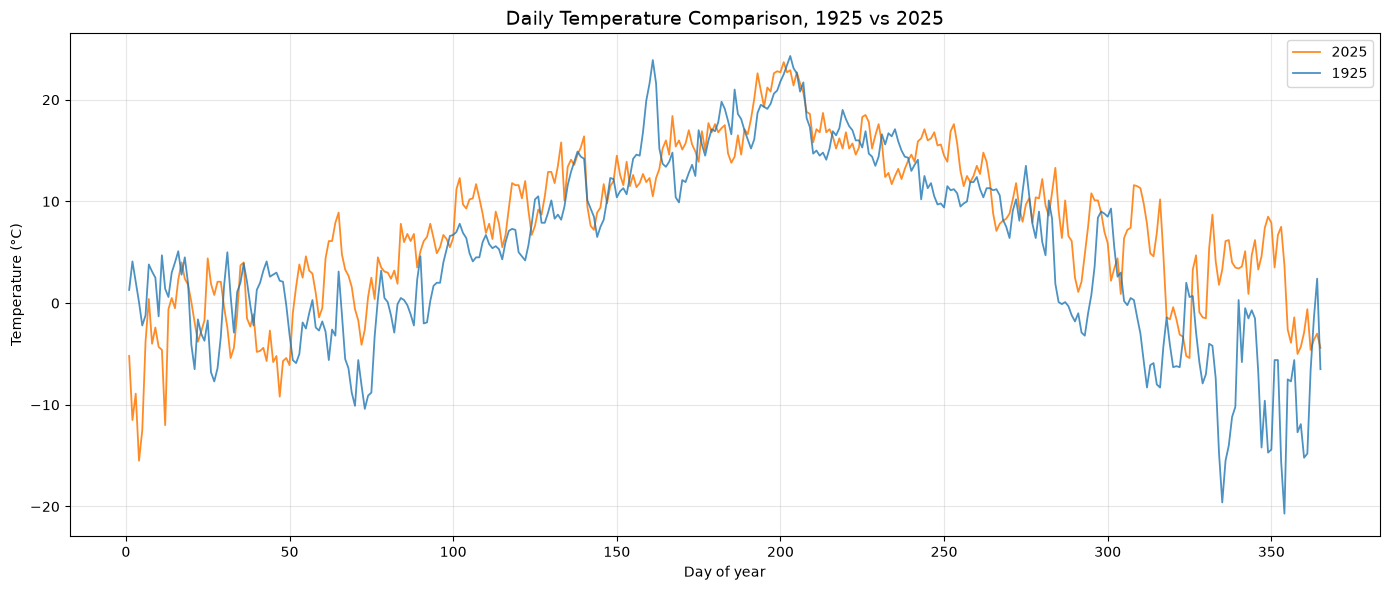


=== Temperature summary 1925 vs 2025 ===
Year  Mean (°C)  Median (°C)  Min (°C)  Max (°C)
2025       7.87          8.3     -15.5      23.7
1925       5.28          5.3     -20.7      24.3


In [ ]:

# ---- Temperature 2025 ----
params_2025 = {                                             # parameters for fetching temperature data for 2025
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
}

r_2025 = requests.get(endpoint, params_2025, auth=(client_id, ""))          # sends the request for temperatures for 2025
json_2025 = r_2025.json()                                                   # converts the response from JSON text to Python dictionaries and lists

if r_2025.status_code == 200:                                               # if the request was successful (status code 200), the data is stored in data_2025
    data_2025 = json_2025["data"]                                           # extracts the list of measurements
    print("Temperature data from 2025 has been fetched")
else:
    print("Error fetching 2025 data:", r_2025.status_code)                  # if not successful, the status code and error message are printed
    print(json_2025.get("error", {}))
    raise SystemExit                                                        # stops the program if the request was not successful

rows_2025 = []
for item in data_2025:
    for obs in item["observations"]:
        rows_2025.append({
            "referenceTime": item["referenceTime"],
            "value": obs["value"],
            "timeOffset": obs["timeOffset"],
        })

df_temp = pd.DataFrame(rows_2025)                                           # creates a table (DataFrame) from all the rows
df_temp["referenceTime"] = pd.to_datetime(df_temp["referenceTime"])         # converts the time text into real date objects
df_temp = df_temp.sort_values("referenceTime").reset_index(drop=True)       # sorts by date and renumbers the rows from 0
df_temp = df_temp.rename(columns={"value": "temperature"})                  # gives the temperature column a clearer name
df_temp = df_temp[df_temp["timeOffset"] == "PT0H"].reset_index(drop=True)   # keeps one observation per day



# ---- Temperature 1925 ----
params_hist = {                                             # parameters for fetching historical temperature data for 1925
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01",
}

r3 = requests.get(endpoint, params_hist, auth=(client_id, ""))      # sends the request for temperatures for 1925. The response is stored in r3
json_hist = r3.json()                                               # converts the response from JSON text to Python dictionaries and lists

if r3.status_code == 200:                                           # if the request was successful (status code 200), the data is stored in data_hist
    data_hist = json_hist["data"]                                   # extracts the list of measurements
    print("Historical temperature data from 1925 has been fetched")
else:
    print("Error fetching historical data:", r3.status_code)        # if not successful, the status code and error message are printed
    print(json_hist.get("error", {}))
    raise SystemExit                                                # stops the program if the request was not successful

rows_hist = []                                                      # goes through each element in data (each element = one point in time)
for item in data_hist:
    for obs in item["observations"]:
        rows_hist.append({
            "referenceTime": item["referenceTime"],
            "value": obs["value"],
            "timeOffset": obs["timeOffset"],
        })

df_1925 = pd.DataFrame(rows_hist)                                           # creates a table (DataFrame) from all the rows
df_1925["referenceTime"] = pd.to_datetime(df_1925["referenceTime"])         # converts the time text into real date objects, so we can calculate with them
df_1925 = df_1925.sort_values(["referenceTime", "timeOffset"])              # sorts by date (and offset)
df_1925 = df_1925.drop_duplicates("referenceTime").reset_index(drop=True)   # keeps one observation per day, so no day is counted twice
df_1925 = df_1925.rename(columns={"value": "temperature_1925"})             # gives the temperature column a clearer name

print(len(df_temp), len(df_1925))                                           # number of days for each year (should be 365)



df_temp["day_of_year"] = df_temp["referenceTime"].dt.dayofyear              # creates a new column with day of year (1-365) for the 2025 data
df_1925["day_of_year"] = df_1925["referenceTime"].dt.dayofyear              # same for 1925, so both years share the same x-axis



plt.figure(figsize=(14, 6))         # creates a new figure, 14 x 6 inches

plt.plot(df_temp["day_of_year"], df_temp["temperature"],
         color="tab:orange", linewidth=1.3, label="2025", alpha=0.9)        

plt.plot(df_1925["day_of_year"], df_1925["temperature_1925"],
         color="tab:blue", linewidth=1.3, label="1925", alpha=0.8)          

plt.title("Daily Temperature Comparison, 1925 vs 2025", fontsize=14)        # title of the figure
plt.xlabel("Day of year")                 # label of the x-axis
plt.ylabel("Temperature (°C)")            # label of the y-axis
plt.legend()                              # shows legend (which colour is which year)
plt.grid(True, alpha=0.3)                 # faint grid in the background
plt.tight_layout()                        # adjusts margins so nothing is cut off
plt.show()                                # shows the figure



summary_both = pd.DataFrame({                           # summarises both years
    "Year": ["2025", "1925"],
    "Mean (°C)": [
        round(df_temp["temperature"].mean(), 2),
        round(df_1925["temperature_1925"].mean(), 2)
    ],
    "Median (°C)": [
        round(df_temp["temperature"].median(), 2),
        round(df_1925["temperature_1925"].median(), 2)
    ],
    "Min (°C)": [
        round(df_temp["temperature"].min(), 2),
        round(df_1925["temperature_1925"].min(), 2)
    ],
    "Max (°C)": [
        round(df_temp["temperature"].max(), 2),
        round(df_1925["temperature_1925"].max(), 2)
    ]
})

print("\n=== Temperature summary 1925 vs 2025 ===")
print(summary_both.to_string(index=False))

Discussion of results - task 3

    Ås station has data all the way back to 1874, so data from 1925 was available. To be able to put them on top of each other we used day of the year on the x-axis. The mean for 2025 was 7.87 degrees versus 5,28 in 1925. The difference is largest in the autumn and early winter, where 1925 had several very cold periods (down to −20.7 °C). The summers were are quite similar. Years can vary a lot, its not smart to draw any conclusions from just there to years alone. A better comparison would be to use averages over a few years or decades


------------------------------------------------------
------------------------Task 4------------------------

In [3]:
import yaml


def count_heatwaves(station_id: str, year: int, client_id: str,         #defines the function count_heatwaves, which takes station id, year, client_id, heatwave threshold, minimum number of days and output file name
                    threshold: float = 27.0, min_days: int = 5,
                    output_file: str = "heatwave_summary.yml"):
    endpoint = "https://frost.met.no/observations/v0.jsonld"        # The address of the Frost endpoint for observations
    params = {
        "sources": station_id,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year + 1}-01-01",      #parameter to fetch data for the whole year
    }                                                           
    
    r = requests.get(endpoint, params, auth=(client_id, ""))       #Sends request to Frost for daily maximum temperatures for the whole year. The response is stored in r
    if r.status_code != 200:                                # If the request was not successful (status code != 200), an exception is raised with an error message
        raise Exception(f"Error fetching data: {r.status_code} – {r.json().get('error')}")     #
    
    data = r.json()["data"]     #extracts the list of measurements from the JSON response
    
    
    rows = []           
    for item in data:                       #for loop that goes through each point in time and each observation 
        for obs in item["observations"]:
            rows.append({
                "date": pd.to_datetime(item["referenceTime"]).date(),
                "max_temp": obs["value"],
                "timeOffset": obs["timeOffset"],
            })
    
    df = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)      #Creates table, sorts by date and numbers the rows from 0
    df = df[df["timeOffset"] == "PT0H"].reset_index(drop=True)              #Keeps only the PT0H version (midnight to midnight), and renumbers the rows
                                                                                    #used because of the issue with two measurements per day
    
    heatwaves = []      
    current_start = None
    current_temps = []
    
    for i, row in df.iterrows():                #for loop that goes through each row in the table and checks whether the temperature is above the threshold
        if row["max_temp"] >= threshold:
            if current_start is None:
                current_start = row["date"]
            current_temps.append(row["max_temp"])
        else:
            if current_start is not None and len(current_temps) >= min_days:        #if there is an ongoing heatwave lasting at least min_days, it is stored in the heatwaves list
                heatwaves.append({
                    "start": str(current_start),
                    "end": str(df.loc[i-1, "date"]),
                    "duration_days": len(current_temps),
                    "max_temperature": round(max(current_temps), 1)
                })
            current_start = None
            current_temps = []
    
   
    if current_start is not None and len(current_temps) >= min_days:        #
        heatwaves.append({
            "start": str(current_start),
            "end": str(df.iloc[-1]["date"]),
            "duration_days": len(current_temps),
            "max_temperature": round(max(current_temps), 1)
        })
    

    summary = {
        "station_id": station_id,
        "year": year,
        "threshold_celsius": threshold,
        "minimum_days": min_days,
        "number_of_heatwaves": len(heatwaves),
        "heatwaves": heatwaves
    }
    
    with open(output_file, "w") as f:
        yaml.dump(summary, f, default_flow_style=False, allow_unicode=True, sort_keys=False)
    
    print(f"Found {len(heatwaves)} heatwave(s). Summary written to {output_file}")
    return summary

heatwave_result = count_heatwaves(
    station_id="SN17850",
    year=2025,
    client_id = client_id,
    output_file="heatwave_summary_2025.yml"
)

Found 1 heatwave(s). Summary written to heatwave_summary_2025.yml


Discussion of results - task 4

    We used the daily maximum temperature, since a temperature ≥ 27 °C is defined as a heatwave. The function goes through the days in order and counts hot days in a row; a cooler day ends the streak, meaning that the loop will break.. It also handles the case where the year ends during a heatwave. The station name is fetched from Frost, so the function works for any station and year. Frost gave two versions of the daily max, PT0H and PT18H, but we used PT0H, the same as in the other tasks. We found one heatwave in Ås in 2025, from 16 to 20 July. A limitation is that the function assumes there are no missing days in the data.


------------------------------------------------------
------------------------Task 5------------------------

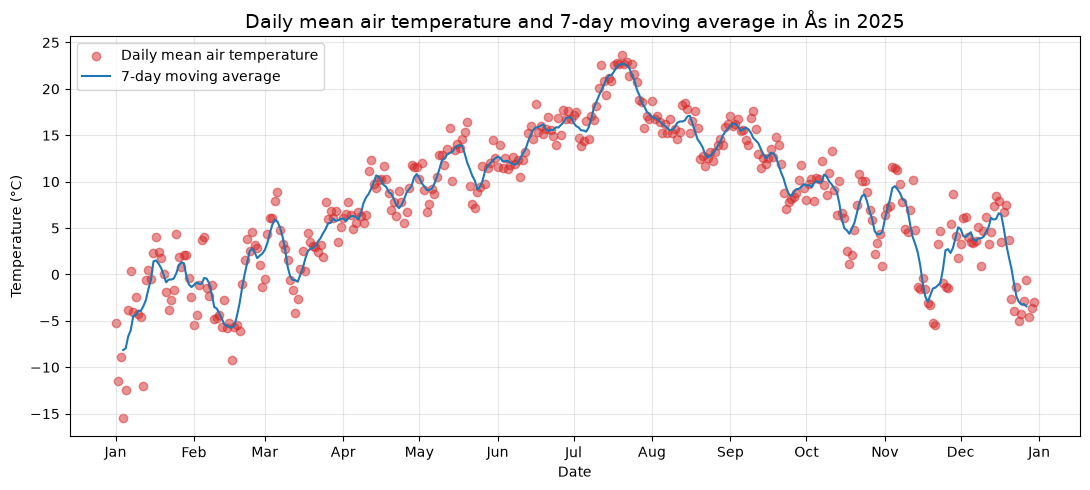

In [7]:
def moving_average(values, window=7):       # function to calculate theseven day moving average
    averages = []                           # create an empty list to store the moving averages
    for i in range(len(values) - window + 1):               # iterate through the values, stopping when there are not enough values left to calculate a full window
        averages.append(values[i:i + window].mean())        # calculate the mean of the current window and append it to the averages list
    return averages



dates = df["time"][3:len(df) - 3]     # dates corresponding to the moving averages (the first and last three days are excluded since they do not have a full 7-day window)



fig, ax = plt.subplots(figsize=(11, 5))         
ax.scatter(df["time"], df["temperature"], color="tab:red", alpha=0.5, label="Daily mean air temperature")      # plots the date on the x-axis and daily mean air temperature data on the y-axis as a scatter plot
ax.plot(dates, moving_average(df["temperature"]), color="tab:blue", label="7-day moving average")      # plots the 7-day moving average of the daily mean air temperature data on the y-axis as a line plot
ax.set_title("Daily mean air temperature and 7-day moving average in Ås in 2025", fontsize=14)
ax.xaxis.set_major_locator(mdates.MonthLocator())           # one tick per month
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
fig.tight_layout()
plt.show()


Discussion of results - task 5

    The seven day moving averages highlights the trends in the temperature. It does so by finding the temperature a given date and the three days prior to and after that date, and then finding the average. We can see that the mean temperatures during the winter don't really line up with the graph for the averages since the temperature varied a lot. However, the temperatures during July line up almost perfectly since there were less abrupt changes.